<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lesson 03 · Applied AI: unstructured data</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">05 · Everything is a vector</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">Can one idea connect words, photos and voices?</p>
</div>

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/03-applied-ai-projects/blob/main/03_multimodal/01_project_everything_is_a_vector/05_Everything_Is_A_Vector.ipynb) [![Slides](https://img.shields.io/badge/slides-Lesson_03-ffd43b)](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#multimodal)

## 🎯 Objectives

By the end you will be able to:

- explain what an **embedding** is: a list of numbers where *similar meaning → nearby points*;
- turn tweets into vectors, draw them on a 2D map and build a **semantic search** that beats keyword search;
- use **CLIP** to search *our own pets* with words, classify cats vs dogs with **zero** training images and find similar photos;
- see that **sound becomes an image** (a spectrogram), transcribe speech with **Whisper** and chain *voice → text → sentiment*.

**📋 Prerequisites:** notebooks 01–04 (TF-IDF, sentiment, CNNs, transfer learning); Lesson 02 PCA · **▶️ How to use:** run the cells in order with `Shift`+`Enter`. The first run downloads three small models (≈ 850 MB in total); after that everything runs offline on a CPU in a few minutes.

## 📑 Contents

0. [⚙️ Setup](#sec-0)
1. [🧭 The big idea: everything is a vector](#sec-1)
2. [📝 Text → vectors (sentence embeddings)](#sec-2)
3. [🔎 Semantic search vs keyword search](#sec-3)
4. [🖼️ CLIP: one space for photos and words](#sec-4)
5. [🔊 Sound → spectrogram → text → sentiment](#sec-5)
6. [✏️ Exercises](#sec-6)
7. [💬 Discussion](#sec-7)
8. [📌 Summary](#sec-8)
9. [📚 Learn more](#sec-9)

<a id="sec-0"></a>

## ⚙️ Setup

In [1]:
# ⚙️ Setup: works locally (VS Code/Jupyter) and in Google Colab
import os
import subprocess
import sys
import time
import warnings
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/03-applied-ai-projects")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/03-applied-ai-projects.git", str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers", "librosa", "soundfile"],
                   check=True)
    os.chdir(ROOT)
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())
sys.path.insert(0, str(ROOT))

# Quieter output: no download bars or library chatter
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_VERBOSITY", "error")
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from IPython.display import Audio, Markdown, display

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()

from src import multimodal as mm
from src.paths import cache_dir, data_dir
from src.plotting import CLASS_COLORS, PALETTE, apply_style, plot_confusion

apply_style()
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
pd.set_option("display.max_colwidth", 90)

DATA = data_dir()
RESULTS = ROOT / "03_multimodal" / "01_project_everything_is_a_vector" / "results"
EXPORT_SLIDES = os.environ.get("NB_EXPORT_SLIDES") == "1"  # only used to refresh the slide images
TIMES = {}  # how long each step takes on this computer


def export(fig, name):
    """Save a compact copy of a figure for the slide deck (off by default): PNG, or WebP if the PNG is > 200 KB."""
    if EXPORT_SLIDES:
        import io

        from PIL import Image as PILImage
        folder = ROOT / "assets" / "slides"
        folder.mkdir(parents=True, exist_ok=True)
        buf = io.BytesIO()
        fig.savefig(buf, format="png", dpi=110)
        if buf.tell() <= 200_000:
            (folder / f"mm-{name}.png").write_bytes(buf.getvalue())
        else:
            img = PILImage.open(buf)
            img.thumbnail((1600, 1600))
            img.save(folder / f"mm-{name}.webp", quality=80, method=6)


def show_photos(fig):
    """Show a figure full of photos as a JPEG (keeps the notebook light) instead of a heavy PNG."""
    import io

    from IPython.display import Image as IPyImage
    buf = io.BytesIO()
    fig.savefig(buf, format="jpg", dpi=80, pil_kwargs={"quality": 82})
    plt.close(fig)
    display(IPyImage(buf.getvalue()))


def skipped(what):
    """Message for cells that need a model that could not be downloaded."""
    print(f"⏭️ Skipped: {what} is not available (see the warning above). Re-run its loading cell once you are online.")


print("Project root:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")
print("Device: CPU is enough for this notebook · torch", torch.__version__, "· transformers", transformers.__version__)

Project root: 03-applied-ai-projects (local)
Device: CPU is enough for this notebook · torch 2.15.0+cpu · transformers 5.24.1


> 💡 **Tip:** locally, run `uv sync` once in the project folder and pick the `.venv` kernel. The three models (MiniLM ≈ 90 MB, CLIP ≈ 600 MB, Whisper-tiny ≈ 150 MB) download on first use into the Hugging Face cache.

<a id="sec-1"></a>

# 1. 🧭 The big idea: everything is a vector

In notebook 01 a sentence became a **bag of words**: one column per word, mostly zeros. In notebook 03 an image became a grid of pixels. Both are numbers, but *bad* numbers for meaning: "my flight was cancelled" and "the airline called off my plane" share almost no words, and two photos of the same cat share almost no pixels.

Modern models fix this with **embeddings**: a short list of numbers (a *vector*) chosen by a neural network so that **things with similar meaning get similar numbers**. Once everything is a vector, one trick works everywhere: *to find similar things, find nearby points.*

### 🧠 How it works

1. **Simple idea:** a model reads a text (or looks at a photo) and outputs, say, 384 numbers. Think of them as GPS coordinates in a "meaning space" with 384 directions instead of 2.
2. **Steps:** the network was trained on millions of examples where it had to put *matching pairs* close together (a question and its answer, a photo and its caption) and *non-matching* pairs far apart.
3. **Analogy:** a supermarket. Nobody tells you the shelf rules, but apples end up near pears and far from detergent. Embeddings learn the shelf layout of language and images.
4. **Limits:** "close" means "used in similar ways in the training data" — not "true", not "same sentiment" (we will see this!), and it inherits the biases of that data.

📖 **Mini-glossary**
- **Embedding / vector:** the list of numbers that represents a text, image or sound.
- **Cosine similarity:** how much two vectors point in the same direction: 1 = same direction, 0 = unrelated. We use it as "similarity of meaning".
- **Encoder:** the network that turns an input into its embedding (MiniLM for sentences, CLIP for images and captions).
- **Multimodal:** dealing with more than one kind of data (text + images + sound).

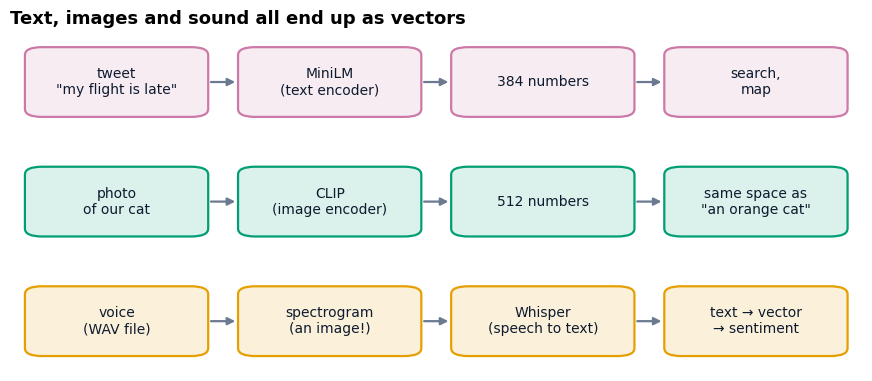

In [2]:
# The three journeys we will take today
fig, axes = plt.subplots(3, 1, figsize=(11, 4.4))
mm.plot_pipeline(["tweet\n\"my flight is late\"", "MiniLM\n(text encoder)", "384 numbers", "search,\nmap"],
                 ax=axes[0], colors=[PALETTE["purple"]] * 4)
mm.plot_pipeline(["photo\nof our cat", "CLIP\n(image encoder)", "512 numbers", "same space as\n\"an orange cat\""],
                 ax=axes[1], colors=[PALETTE["green"]] * 4)
mm.plot_pipeline(["voice\n(WAV file)", "spectrogram\n(an image!)", "Whisper\n(speech to text)", "text\n→ sentiment"],
                 ax=axes[2], colors=[PALETTE["orange"]] * 4)
axes[0].set_title("Text, images and sound all end up as vectors")
plt.show()

<a id="sec-2"></a>

# 2. 📝 Text → vectors (sentence embeddings)

We use **`all-MiniLM-L6-v2`** from the `sentence-transformers` library: a small Transformer (22 M parameters, ≈ 90 MB) trained on more than a billion sentence pairs. It turns any sentence into **384 numbers** and runs comfortably on a CPU. It is the same family of models you met as "sentence embeddings + LogReg" in notebook 02 — now we look at the vectors themselves.

In [3]:
t0 = time.perf_counter()
text_model = mm.try_load("MiniLM (sentence embeddings)", mm.load_text_model)  # downloads ≈ 90 MB the first time
TEXT_OK = text_model is not None
if TEXT_OK:
    v = mm.embed_texts(["My flight got cancelled again"])[0]
    TIMES["load MiniLM"] = time.perf_counter() - t0
    print(f"One sentence → a vector of {v.shape[0]} numbers (length {np.linalg.norm(v):.2f})")
    print("First 8 numbers:", np.round(v[:8], 3))

One sentence → a vector of 384 numbers (length 1.00)
First 8 numbers: [ 0.054 -0.05   0.033  0.082 -0.026 -0.037  0.022 -0.038]


Those numbers mean nothing on their own. What matters is how they **compare**. Let's embed six sentences — three pairs that say the same thing with (almost) *different words* — and compute the cosine similarity of every pair.

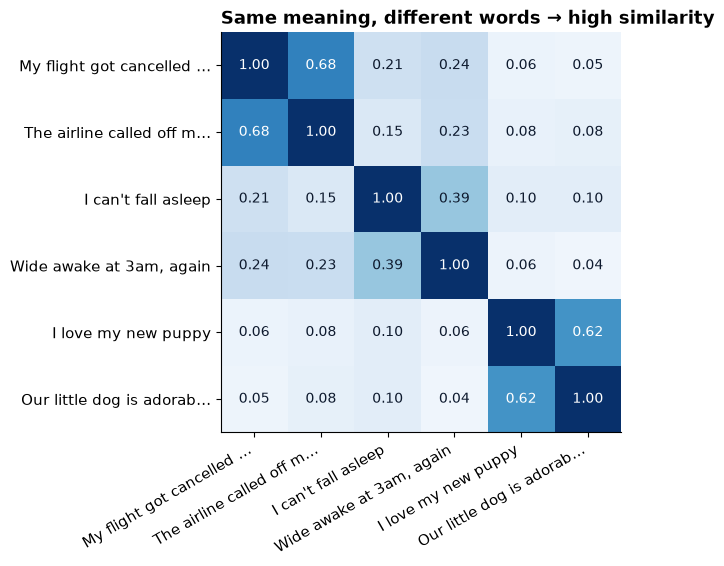

Words shared by the flight pair: 0 · by the sleep pair: 0 · by the dog pair: 0


In [4]:
if TEXT_OK:
    sentences = [
        "My flight got cancelled again",
        "The airline called off my plane today",
        "I can't fall asleep",
        "Wide awake at 3am, again",
        "I love my new puppy",
        "Our little dog is adorable",
    ]
    S = mm.cosine_similarity(mm.embed_texts(sentences), mm.embed_texts(sentences))
    shared = np.array([[len(set(mm.tokenize(a)) & set(mm.tokenize(b))) for b in sentences] for a in sentences])

    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    ax.imshow(S, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(sentences)):
        for j in range(len(sentences)):
            ax.text(j, i, f"{S[i, j]:.2f}", ha="center", va="center", fontsize=10,
                    color="white" if S[i, j] > 0.6 else PALETTE["navy"])
    short = [s if len(s) < 26 else s[:24] + "…" for s in sentences]
    ax.set_xticks(range(6), short, rotation=30, ha="right")
    ax.set_yticks(range(6), short)
    ax.grid(False)
    ax.set_title("Same meaning, different words → high similarity")
    plt.show()
    print("Words shared by the flight pair:", shared[0, 1], "· by the sleep pair:", shared[2, 3], "· by the dog pair:", shared[4, 5])
else:
    skipped('MiniLM')

👀 **What to notice:** each pair scores much higher with its partner than with the others, although the pairs share almost **no words** (look at the last line). A bag-of-words or TF-IDF model (notebook 01) would say they are unrelated.

Now the real data: the tweets from notebook 02. To keep it fast we embed **10,000 tweets**: *every* negative tweet (complaints make good search examples) plus a random sample of positive ones. On a laptop CPU this takes about a minute the first time; the vectors are then saved in `data/_cache/` so the next run is instant.

In [5]:
tweets = pd.read_csv(DATA / "tweets" / "tweets_train.csv")
tweets = tweets[tweets["text"].fillna("").str.strip().str.len() > 0].drop_duplicates("text")
neg = tweets[tweets["class"] == "neg"]
pos = tweets[tweets["class"] == "pos"].sample(10_000 - len(neg), random_state=SEED)
corpus = pd.concat([neg, pos]).sort_values("tweet").reset_index(drop=True)

cache = cache_dir() / f"nb05_tweet_vectors_{len(corpus)}.npz"
t0 = time.perf_counter()
corpus_vecs = None
if cache.exists() and np.array_equal(np.load(cache)["ids"], corpus["tweet"].to_numpy()):
    corpus_vecs = np.load(cache)["vecs"]
    print("Loaded cached vectors from", cache.name)
elif TEXT_OK:
    corpus_vecs = mm.embed_texts(corpus["text"].tolist())
    np.savez_compressed(cache, ids=corpus["tweet"].to_numpy(), vecs=corpus_vecs)
else:
    skipped("MiniLM")
VECS_OK = corpus_vecs is not None
SEARCH_OK = TEXT_OK and VECS_OK  # searching needs the model (for the query) and the tweet vectors
if VECS_OK:
    TIMES["embed 10k tweets"] = time.perf_counter() - t0
    print(f"{len(corpus):,} tweets → matrix {corpus_vecs.shape} in {TIMES['embed 10k tweets']:.0f} s")
print(corpus["class"].value_counts().to_dict())

Loaded cached vectors from nb05_tweet_vectors_10000.npz
10,000 tweets → matrix (10000, 384) in 0 s
{'neg': 6756, 'pos': 3244}


### 🗺️ A map of meaning

384 dimensions are impossible to see, so we squash them to 2D. In Lesson 02 you used **PCA**; here we use **t-SNE**, which cares about keeping *neighbours* together (great for maps, but distances between far-away groups mean little). We take 2,000 tweets (1,000 of each class), then use K-Means (Lesson 02) to cut the map into 14 regions and label each region with its most typical words (TF-IDF from notebook 01).

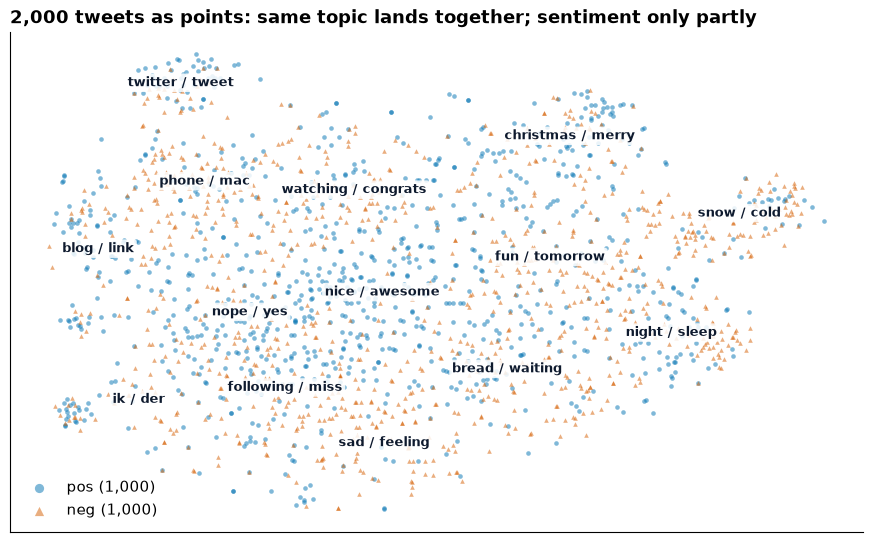

group,11,12,10,9,4,1,3,0,6,5,7,2,8,13
tweets,128,119,150,166,163,155,162,159,104,149,82,124,170,169
top words,snow / cold,sad / feeling,phone / mac,fun / tomorrow,bread / waiting,night / sleep,watching / congrats,following / miss,ik / der,christmas / merry,twitter / tweet,blog / link,nope / yes,nice / awesome
% negative,76,76,65,58,56,55,51,51,50,38,37,36,36,19


In [6]:
if VECS_OK:
    from sklearn.cluster import KMeans
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer

    idx_map = np.concatenate([
        corpus.index[corpus["class"] == c].to_series().sample(1000, random_state=SEED).to_numpy() for c in ("neg", "pos")
    ])
    sub, sub_vecs = corpus.loc[idx_map].reset_index(drop=True), corpus_vecs[idx_map]
    t0 = time.perf_counter()
    xy = mm.project_2d(sub_vecs, method="tsne", seed=SEED)
    groups = KMeans(n_clusters=14, random_state=SEED, n_init=10).fit_predict(xy)
    TIMES["t-SNE + K-Means"] = time.perf_counter() - t0

    stop = list(ENGLISH_STOP_WORDS | {"just", "got", "url", "user", "lol", "im", "day", "today", "like", "know",
                                      "don", "amp", "quot", "good", "really", "ll", "ve", "going", "time", "get", "oh", "ma",
                                      "want", "need", "think", "make", "did", "didn", "ok", "haha", "yeah", "new",
                                      "great", "hope", "thanks", "thank", "love", "work", "home", "gonna", "wanna", "sorry"})
    tfidf = TfidfVectorizer(stop_words=stop, min_df=3)
    X_words = tfidf.fit_transform(sub["text"])
    vocab = np.array(tfidf.get_feature_names_out())

    fig, ax = plt.subplots(figsize=(11, 6.5))
    for cls, marker in (("pos", "o"), ("neg", "^")):
        m = (sub["class"] == cls).to_numpy()
        ax.scatter(xy[m, 0], xy[m, 1], s=11, alpha=0.5, c=CLASS_COLORS[cls], marker=marker, lw=0,
                   label=f"{cls} ({m.sum():,})")
    topics = []
    for g in range(14):
        m = groups == g
        words = vocab[np.asarray(X_words[m].mean(axis=0)).ravel().argsort()[::-1][:2]]
        share_neg = (sub["class"][m] == "neg").mean()
        topics.append({"group": g, "tweets": m.sum(), "top words": " / ".join(words), "% negative": round(100 * share_neg)})
        cx, cy = np.median(xy[m], axis=0)
        ax.annotate(" / ".join(words), (cx, cy), ha="center", fontsize=9.5, weight="bold", color=PALETTE["navy"],
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.legend(markerscale=2, loc="lower left")
    ax.set_title("2,000 tweets as points: same topic lands together; sentiment only partly")
    export(fig, "tweet-map")
    plt.show()
    display(pd.DataFrame(topics).sort_values("% negative", ascending=False).set_index("group").T)
else:
    skipped('the tweet vectors')

👀 **What to notice:** tweets cluster by **topic** (sleep, snow, Christmas, phones, Twitter itself…) far more than by sentiment — there is even a small island of tweets in **Dutch** ("ik", "der"): the model noticed a different language without being told. Some regions are mostly negative (feeling sad, cold weather), others mostly positive ("nice / awesome"), but most mix both colours. That is why in notebook 02 sentence embeddings + LogReg did *not* crush TF-IDF on sentiment: MiniLM was trained to capture **what** a sentence is about, not **how** the author feels.

> 🧠 **Takeaway:** an embedding is only as good as the job it was trained for. Similar *topic* ≠ similar *opinion*.

<a id="sec-3"></a>

# 3. 🔎 Semantic search vs keyword search

**Keyword search** (what `Ctrl`+`F` does) returns documents that contain your words. **Semantic search** embeds your query and returns the *nearest vectors*, so it can find documents with the same meaning and none of your words.

| | Keyword search | Semantic search |
|---|---|---|
| Matches | exact words | meaning |
| "plane" finds "flight"? | ❌ | ✅ |
| Speed | very fast, no model | one embedding + one matrix product |
| Fails when | synonyms, typos, other phrasings | rare names/codes, negations ("not delayed") |

In [7]:
if SEARCH_OK:
    def compare_search(query, k=5):
        """Top-k tweets from keyword search and from semantic search, side by side."""
        kw_idx, kw_scores = mm.keyword_search(query, corpus["text"].tolist(), k=k)
        se_idx, se_scores = mm.top_k(mm.embed_texts([query]), corpus_vecs, k=k)
        kw = [f"({s:.0f} words) {corpus.text[i][:70]}" for i, s in zip(kw_idx, kw_scores)]
        se = [f"({s:.2f}) {corpus.text[i][:70]}" for i, s in zip(se_idx, se_scores)]
        kw += ["— nothing —"] * (k - len(kw))
        return pd.DataFrame({"🔤 keyword search": kw, "🧭 semantic search": se}, index=range(1, k + 1))


    t0 = time.perf_counter()
    for query in ["my plane is late", "stuck awake all night"]:
        display(Markdown(f"**Query:** `{query}`"))
        display(compare_search(query))
    TIMES["2 searches"] = time.perf_counter() - t0
else:
    skipped('MiniLM')

**Query:** `my plane is late`

,🔤 keyword search,🧭 semantic search
1,"(1 words) Waiting for furnace cleaners, they're late and I wanna go back to slee",(0.62) Im in the plane
2,(1 words) It's way too late I believe. Another year of suckage,(0.59) Flight delayed by 20 mins. May be i should be delighted? Got 2 more ho
3,(1 words) They changed our plane from a 737 to a 767. That means no exit row for,(0.58) Flight delayed yet again this is really annoying! I wanna get the hel
4,"(1 words) Woke up late this morning, but got to work on time. Sorry, no blog pos","(0.57) have a safe trip, planes freak me out"
5,(1 words) At the stila warehouse sale. Ughh woke up late! Looks like I'm going t,(0.57) Really early flight.


**Query:** `stuck awake all night`

,🔤 keyword search,🧭 semantic search
1,(3 words) I couldnt sleep at all last night. I literally laid in my bed awake ag,(0.68) Sleepless again
2,(2 words) Time for beddie bye. Last day of vay-kay tomorrow ... . Nightie night,(0.63) Awake in the small hours
3,(2 words) Poor muffin Does that mean you're not feeling better or that you want,(0.61) Trying to go back to sleep
4,(2 words) Sleepy from all the ruccus last night,(0.59) I couldnt sleep at all last night. I literally laid in my bed awake ag
5,"(2 words) All BabyKea wants for Christmas are her two front teeth. Until then,",(0.59) Can't sleep


👀 **What to notice:** for *"my plane is late"* keyword search grabs any tweet with "late" (late for work, late birthday wishes…), while semantic search finds **delayed and cancelled flights**, even though none of them says "plane is late". And searching 10,000 tweets took a fraction of a second: one matrix product.

> 💡 Real systems often combine both (**hybrid search**): keywords for exact names and codes, vectors for meaning.

<a id="sec-4"></a>

# 4. 🖼️ CLIP: one space for photos and words

In notebook 04 we *trained* a CNN to tell cats from dogs with thousands of labelled photos. **CLIP** (OpenAI, 2021) took a different route: it learned from **400 million photos with their captions** from the web. It has two encoders — one for images, one for text — trained so that a photo and *its* caption land on the **same point**.

### 🧠 How it works
1. **Simple idea:** photo → 512 numbers; caption → 512 numbers *in the same space*.
2. **Steps:** in each training batch, CLIP sees N photos and N captions and learns to make the N correct pairs close and the N² − N wrong pairs far (*contrastive learning*).
3. **Analogy:** a bilingual dictionary where one language is "pictures".
4. **Limits:** it only knows concepts that appear in web captions, it reads text written *inside* images surprisingly well (and can be fooled by it), and it copies the stereotypes of the web.

This gives us three superpowers for free: **search photos with words**, **classify without training** (*zero-shot*) and **find similar photos**. We use `openai/clip-vit-base-patch32` (≈ 600 MB, fine on CPU).

In [8]:
# Our pets (explicit, sorted file lists: labels can never get shuffled) + a few photos from notebook 04's dataset
pets_files = sorted((DATA / "pets" / "cropped" / "cats").glob("*.jpg")) + sorted((DATA / "pets" / "cropped" / "dogs").glob("*.jpg"))
pets_labels = np.array(["cat" if f.parent.name == "cats" else "dog" for f in pets_files])


def first_n(split, n_per_class=50):
    files = []
    for cls in ("cats", "dogs"):
        folder = DATA / "cats_and_dogs" / split / cls
        files += sorted(folder.glob("*.jpg"), key=lambda p: int(p.stem.split(".")[1]))[:n_per_class]
    return files


train_files, val_files = first_n("train"), first_n("validation")
label_of = lambda files: np.array(["cat" if f.parent.name == "cats" else "dog" for f in files])

t0 = time.perf_counter()
clip = mm.try_load("CLIP", mm.load_clip)  # ≈ 600 MB the first time
CLIP_OK = clip is not None
if CLIP_OK:
    TIMES["load CLIP"] = time.perf_counter() - t0
    t0 = time.perf_counter()
    pets_vecs = mm.clip_embed_images(pets_files)
    val_vecs = mm.clip_embed_images(val_files)
    train_vecs = mm.clip_embed_images(train_files)
    TIMES["CLIP: embed 217 photos"] = time.perf_counter() - t0
    print(f"{len(pets_files)} pets ({(pets_labels == 'cat').sum()} cats, {(pets_labels == 'dog').sum()} dogs), "
          f"{len(val_files)} validation and {len(train_files)} training photos → vectors of {pets_vecs.shape[1]} numbers "
          f"in {TIMES['CLIP: embed 217 photos']:.0f} s")

17 pets (10 cats, 7 dogs), 100 validation and 100 training photos → vectors of 512 numbers in 20 s


### 🔤→🖼️ Search our pets with words

We embed a few descriptions and, for each, show the three closest pet photos with their cosine similarity. No pet was ever labelled with these words.

In [9]:
from PIL import Image


def show_grid(rows, row_titles, ncols, suptitle, cell=2.3):
    """rows = list of lists of (path, caption)."""
    fig, axes = plt.subplots(len(rows), ncols, figsize=(cell * ncols + 2.2, cell * len(rows)), squeeze=False)
    for r, (row, title) in enumerate(zip(rows, row_titles)):
        for c in range(ncols):
            ax = axes[r, c]
            ax.axis("off")
            if c < len(row):
                path, caption = row[c]
                img = Image.open(path).convert("RGB")
                img.thumbnail((300, 300))
                ax.imshow(img)
                ax.set_title(caption, fontsize=9.5, loc="center", fontweight="normal")
        axes[r, 0].text(-0.08, 0.5, title, transform=axes[r, 0].transAxes, ha="right", va="center",
                        fontsize=11, fontweight="bold", color=PALETTE["navy"], wrap=True)
    fig.suptitle(suptitle, x=0.02, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout()
    return fig

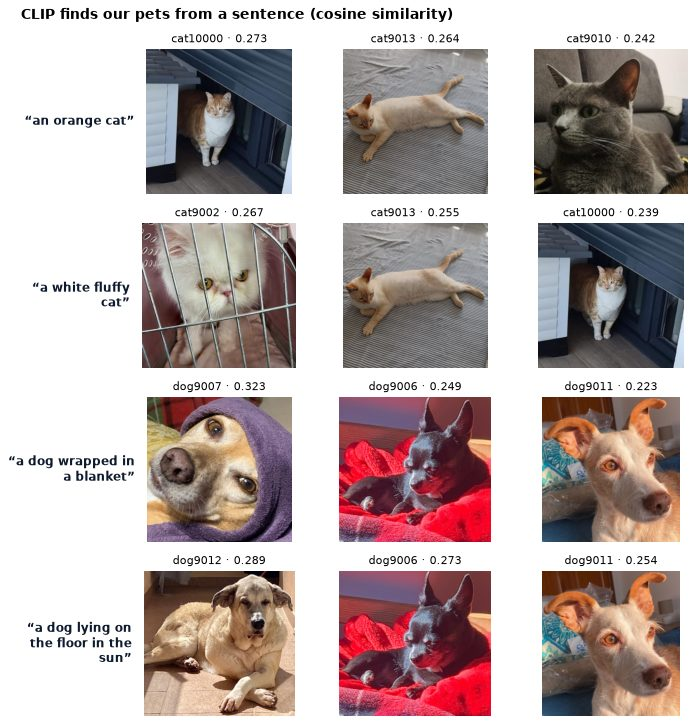

In [10]:
if CLIP_OK:
    queries = ["an orange cat", "a white fluffy cat", "a dog wrapped in a blanket", "a dog lying on the floor in the sun"]
    query_vecs = mm.clip_embed_texts(queries)
    rows = []
    for qv in query_vecs:
        idx, scores = mm.top_k(qv, pets_vecs, k=3)
        rows.append([(pets_files[i], f"{pets_files[i].stem} · {s:.3f}") for i, s in zip(idx, scores)])
    fig = show_grid(rows, [f"“{q}”" for q in queries], 3, "CLIP finds our pets from a sentence (cosine similarity)")
    export(fig, "clip-search")
    show_photos(fig)
else:
    skipped('CLIP')

👀 **What to notice:** the similarities look small (≈ 0.25–0.33) — that is normal for CLIP, where text and image vectors never get very close. What matters is the **ranking**: the right pets come first. Try your own descriptions in Exercise 2.

### 🎯 Zero-shot classification: cat or dog with zero training photos

Turn each class into a sentence — *"a photo of a cat"*, *"a photo of a dog"* — and give each photo the class whose sentence is closest. To get percentages, CLIP multiplies the cosine similarities by ≈ 100 and applies a **softmax**, so the scores of the sentences on offer add up to 100%.

> ⚠️ These are **relative scores over the sentences we chose**, not a calibrated confidence. With only "cat" and "dog" on the menu, even a photo of a toaster gets 100% split between cat and dog; add a third sentence and every score changes. (Notebook 04's model works differently: a single output number and a *sigmoid* that gives P(dog) directly.)

Zero-shot accuracy · our pets: 94% (16/17) · validation photos: 100% (100/100)


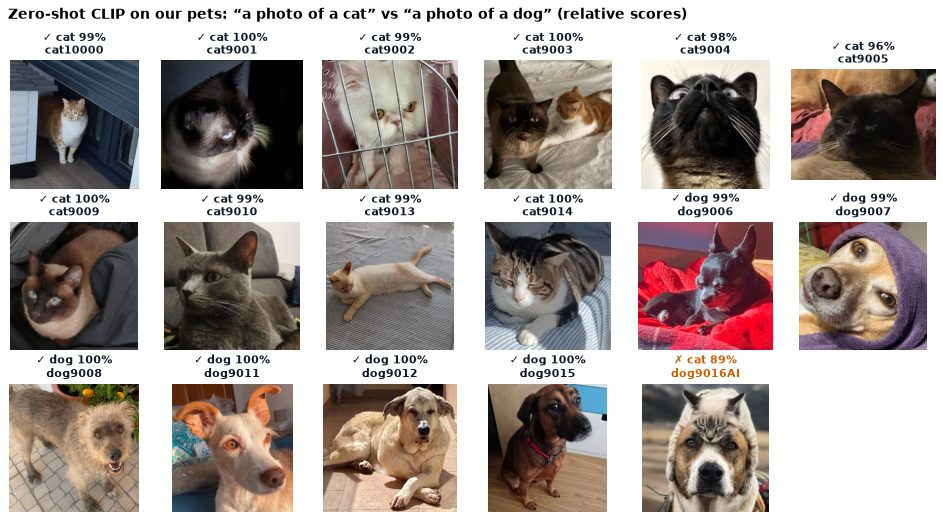

In [11]:
if CLIP_OK:
    labels = ["cat", "dog"]
    prompt_vecs = mm.clip_embed_texts([f"a photo of a {c}" for c in labels])
    p_pets = mm.zero_shot_probs(pets_vecs, prompt_vecs)          # rows = photos, columns = [cat, dog]
    pred_pets = np.array(labels)[p_pets.argmax(axis=1)]
    p_val = mm.zero_shot_probs(val_vecs, prompt_vecs)
    pred_val = np.array(labels)[p_val.argmax(axis=1)]

    acc_pets, acc_val = (pred_pets == pets_labels).mean(), (pred_val == label_of(val_files)).mean()
    print(f"Zero-shot accuracy · our pets: {acc_pets:.0%} ({(pred_pets == pets_labels).sum()}/{len(pets_files)}) · "
          f"validation photos: {acc_val:.0%} ({(pred_val == label_of(val_files)).sum()}/{len(val_files)})")

    fig, axes = plt.subplots(3, 6, figsize=(12, 6.6))
    for ax, f, p, y in zip(axes.ravel(), pets_files, p_pets, pets_labels):
        img = Image.open(f).convert("RGB")
        img.thumbnail((300, 300))
        ax.imshow(img)
        guess = labels[p.argmax()]
        mark = "✓" if guess == y else "✗"
        ax.set_title(f"{mark} {guess} {p.max():.0%}\n{f.stem}", fontsize=9.5, loc="center",
                     color=PALETTE["navy"] if guess == y else PALETTE["red"])
    for ax in axes.ravel():
        ax.axis("off")
    fig.suptitle("Zero-shot CLIP on our pets: “a photo of a cat” vs “a photo of a dog” (relative scores)", x=0.02, ha="left",
                 fontsize=13, fontweight="bold")
    fig.tight_layout()
    show_photos(fig)
else:
    skipped('CLIP')

👀 **What to notice:** every real pet is right, most with relative scores ≥ 96%. The only "mistake" is **`dog9016AI`**, the AI-generated dog wearing a cat on its head: CLIP says *cat*. Is that wrong? The photo really contains both — with only two options, the softmax must pick one. Real or AI-generated, the model does not care: it only sees pixels.

### ⚖️ Zero-shot vs trained models

How does "no training at all" compare with models that saw labelled photos? We compare three things on the same photos:

1. **CLIP zero-shot** — 0 labelled photos, just two sentences;
2. **linear probe** — a Logistic Regression (Lesson 02!) trained on the CLIP vectors of only **100** labelled photos (this is transfer learning in one line);
3. **notebook 04's model** — a pretrained MobileNet with a logistic head trained on 2,000 labelled photos; we load the predictions on our pets it saved in `results/pets_predictions.json` (if that file is missing, we simply skip it).

Loaded notebook 04 predictions from pets_predictions.json (17 pets)


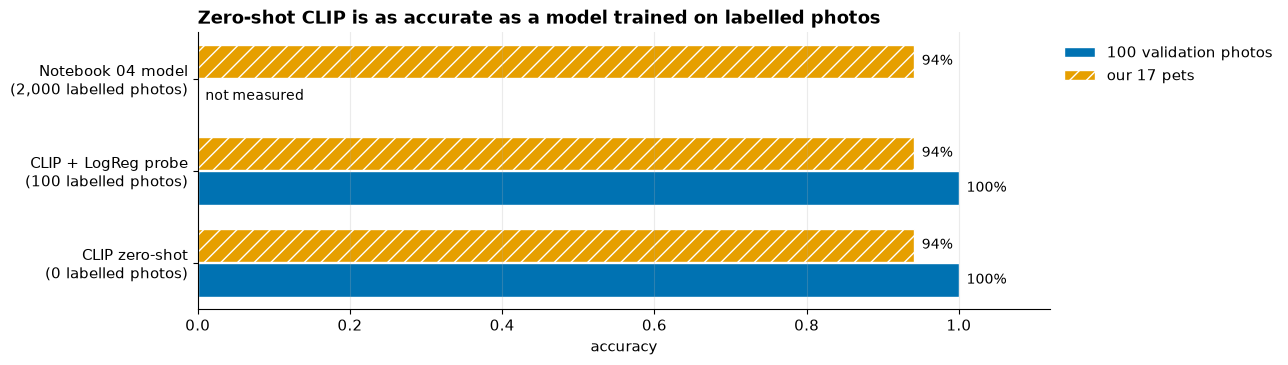

,100 validation photos,our 17 pets
CLIP zero-shot (0 labelled photos),100%,94%
CLIP + LogReg probe (100 labelled photos),100%,94%
"Notebook 04 model (2,000 labelled photos)",—,94%


In [12]:
if CLIP_OK:
    from sklearn.linear_model import LogisticRegression

    probe = LogisticRegression(max_iter=2000, random_state=SEED).fit(train_vecs, label_of(train_files))
    acc = {
        "CLIP zero-shot\n(0 labelled photos)": (acc_val, acc_pets),
        "CLIP + LogReg probe\n(100 labelled photos)": ((probe.predict(val_vecs) == label_of(val_files)).mean(),
                                                        (probe.predict(pets_vecs) == pets_labels).mean()),
    }
    nb04 = mm.load_trained_pet_predictions(ROOT / "02_computer_vision" / "02_project_cats_vs_dogs" / "results")
    if nb04 is not None:
        truth = dict(zip([f.name for f in pets_files], pets_labels))
        nb04 = nb04[nb04["file"].isin(truth)]
        acc["Notebook 04 model\n(2,000 labelled photos)"] = (np.nan, (nb04["pred"] == nb04["file"].map(truth)).mean())
        print(f"Loaded notebook 04 predictions from {nb04.attrs.get('source')} ({len(nb04)} pets)")
    else:
        print("Notebook 04 predictions not found (run notebook 04 first if you want that comparison) — showing CLIP only.")

    table = pd.DataFrame(acc, index=["100 validation photos", f"our {len(pets_files)} pets"]).T
    fig, ax = plt.subplots(figsize=(11, 3.6))
    names = list(table.index)
    ypos = np.arange(len(names))
    for k, (col, colour, hatch) in enumerate(zip(table.columns, [PALETTE["blue"], PALETTE["orange"]], ["", "//"])):
        vals = table[col].to_numpy(dtype=float)
        ax.barh(ypos + (k - 0.5) * 0.38, np.nan_to_num(vals), height=0.36, color=colour, hatch=hatch,
                edgecolor="white", label=col)
        for y, v in zip(ypos + (k - 0.5) * 0.38, vals):
            ax.text((0 if np.isnan(v) else v) + 0.01, y, "not measured" if np.isnan(v) else f"{v:.0%}",
                    va="center", fontsize=10)
    ax.set_yticks(ypos, names)
    ax.set_xlim(0, 1.12)
    ax.set_xlabel("accuracy")
    ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
    ax.grid(axis="y", visible=False)
    ax.set_title("Zero-shot CLIP is as accurate as a model trained on labelled photos")
    export(fig, "zero-shot-vs-trained")
    plt.show()
    display(table.style.format("{:.0%}", na_rep="—"))
else:
    skipped('CLIP')

👀 **What to notice:** CLIP with *zero* training images is about as good as models trained for the job. That is the power of **pre-training on huge data**: the hard work (learning what cats and dogs look like) was done once, by someone else, and we reuse it — the same idea as transfer learning in notebook 04, pushed to the limit.

But zero-shot is not magic: for things that are rare on the web (a specific machine defect, a medical scan, *your* cat vs *your neighbour's* cat) you still need labelled data and fine-tuning.

### 🖼️→🖼️ Find similar photos

Image vectors can also be compared with each other: give a photo, get its nearest neighbours among our pets plus the 200 photos from notebook 04's dataset.

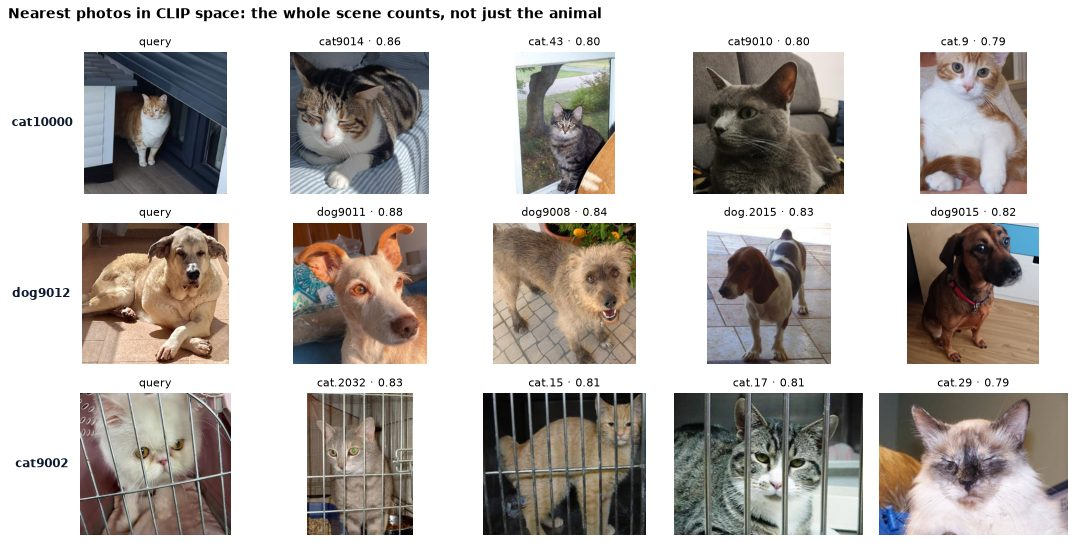

In [13]:
if CLIP_OK:
    pool_files = pets_files + val_files + train_files
    pool_vecs = np.vstack([pets_vecs, val_vecs, train_vecs])
    rows, titles = [], []
    for name in ["cat10000", "dog9012", "cat9002"]:
        q = next(i for i, f in enumerate(pool_files) if f.stem == name)
        idx, scores = mm.top_k(pool_vecs[q], pool_vecs, k=4, exclude=[q])
        rows.append([(pool_files[q], "query")] + [(pool_files[i], f"{pool_files[i].stem} · {s:.2f}") for i, s in zip(idx, scores)])
        titles.append(name)
    fig = show_grid(rows, titles, 5, "Nearest photos in CLIP space: the whole scene counts, not just the animal")
    show_photos(fig)
else:
    skipped('CLIP')

👀 **What to notice:** `cat9002` sits behind the bars of a carrier — and its neighbours are **other cats behind bars**. `dog9012` finds mostly *our other dogs*: same floors, same light, same phone camera. CLIP vectors describe the **whole scene** (background, lighting, framing), not only the animal. That is how "more like this" and reverse image search work — and a warning: a model can learn the background instead of the object.

<a id="sec-5"></a>

# 5. 🔊 Sound → spectrogram → text → sentiment

A microphone measures air pressure thousands of times per second. Our clips use **16,000 numbers per second** (16 kHz) — a 4-second sentence is 64,000 numbers in a row, the **waveform**. The waveform shows *when* there is sound, but not *which* sound.

A **spectrogram** answers that: cut the sound into tiny windows (10 ms), measure how much energy each pitch has in each window, and stack the windows side by side. The result is an **image** (time × pitch). And images are something you already know how to handle: the CNN ideas from notebook 04 apply directly. Speech models like Whisper "look" at this picture.

📖 **Mini-glossary**
- **Sample rate:** numbers per second (16 kHz = 16,000).
- **Mel scale:** a pitch scale that matches human hearing (more detail at low pitches, where speech lives).
- **ASR (automatic speech recognition):** speech → text.

Our clips in `data/audio/` were made with the Windows text-to-speech voices (no real person recorded). Listen to one:

In [14]:
SHIPPED = ["flight_cancelled", "lisbon_weather", "lost_luggage", "new_puppy", "question_travel",
           "pictionary_purple_blanket"]  # the clips that come with the lesson (the last one is for Challenge 3)
clips = {name: DATA / "audio" / f"{name}.wav" for name in SHIPPED}
truth = {
    "flight_cancelled": ("My flight got cancelled again. This is the worst day ever.", "neg"),
    "lisbon_weather": ("Just landed in Lisbon and the weather is amazing!", "pos"),
    "lost_luggage": ("The airline lost my luggage and nobody at the desk will help me.", "neg"),
    "new_puppy": ("We adopted a puppy today and I am so happy I could cry.", "pos"),
}
audio = {name: mm.load_audio(path)[0] for name, path in clips.items()}
for name, y in audio.items():
    print(f"{name:18s} {len(y):6,} numbers = {len(y) / mm.SAMPLE_RATE:.1f} s")
display(Audio(audio["flight_cancelled"], rate=mm.SAMPLE_RATE))

flight_cancelled   82,720 numbers = 5.2 s
lisbon_weather     56,000 numbers = 3.5 s
lost_luggage       72,560 numbers = 4.5 s
new_puppy          71,280 numbers = 4.5 s
question_travel    62,880 numbers = 3.9 s
pictionary_purple_blanket 68,560 numbers = 4.3 s


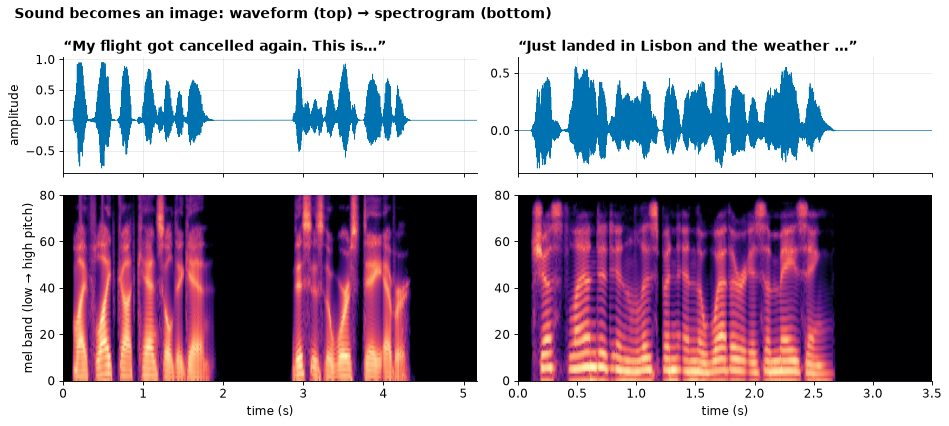

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 5.4), sharex="col", gridspec_kw={"height_ratios": [1, 1.6]})
for col, name in enumerate(["flight_cancelled", "lisbon_weather"]):
    mm.plot_waveform_and_spectrogram(audio[name], axes=axes[:, col], title=f"“{truth[name][0][:38]}…”")
    if col:
        axes[0, col].set_ylabel("")
        axes[1, col].set_ylabel("")
fig.suptitle("Sound becomes an image: waveform (top) → spectrogram (bottom)", x=0.02, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
export(fig, "spectrogram")
show_photos(fig)

👀 **What to notice:** in the spectrogram each **word** is a block of bright vertical stripes, and the horizontal bands are the *harmonics* of the voice. Silence is dark. A CNN can learn that a certain shape means "s" or "a" exactly as it learned that a certain shape means "ear" or "whisker".

### 🗣️ Whisper: speech → text

**Whisper** (OpenAI, 2022) was trained on 680,000 hours of speech from the web in ~100 languages. We use the **tiny** version (39 M parameters, ≈ 150 MB): fast on CPU and good enough for clear speech. We give it the raw numbers directly, so no extra audio software (ffmpeg) is needed.

📏 We score it with the **word error rate (WER)**, the standard speech-to-text metric: line up the words *in order* and count substitutions, deletions and insertions, divided by the number of words said (capital letters and punctuation are ignored). 0% = perfect; "flight my" for "my flight" is *not* perfect.

In [16]:
t0 = time.perf_counter()
WHISPER_OK = mm.try_load("Whisper-tiny", mm.load_whisper) is not None  # ≈ 150 MB the first time
if WHISPER_OK:
    TIMES["load Whisper"] = time.perf_counter() - t0
    t0 = time.perf_counter()
    transcripts = {name: mm.transcribe(audio[name]) for name in truth}
    TIMES["Whisper: 4 clips"] = time.perf_counter() - t0
    print(f"Transcribed {sum(len(audio[n]) for n in truth) / mm.SAMPLE_RATE:.0f} s of speech in {TIMES['Whisper: 4 clips']:.1f} s")
else:  # keep the rest of the section alive with the known sentences
    transcripts = {name: truth[name][0] for name in truth}
    print("⏭️ Whisper unavailable: using the known sentences instead, so the sentiment step below still runs.")

asr = pd.DataFrame({"what was said": [truth[n][0] for n in truth], "what Whisper heard": list(transcripts.values())},
                   index=list(truth))
asr["WER"] = [mm.word_error_rate(a, b) for a, b in zip(asr["what was said"], asr["what Whisper heard"])]
asr["exact words?"] = asr["WER"] == 0
asr.style.format({"WER": "{:.0%}"})

Transcribed 18 s of speech in 8.3 s


,what was said,what Whisper heard,WER,exact words?
flight_cancelled,My flight got cancelled again. This is the worst day ever.,My flight got cancelled again. This is the worst day ever.,0%,True
lisbon_weather,Just landed in Lisbon and the weather is amazing!,Just landed in Lisbon and the weather is amazing.,0%,True
lost_luggage,The airline lost my luggage and nobody at the desk will help me.,The airline lost my luggage and nobody at the desk will help me.,0%,True
new_puppy,We adopted a puppy today and I am so happy I could cry.,We adopted a puppy today and I am so happy I could cry.,0%,True


### 😊😠 Voice → text → sentiment

Now we chain it with the text world. We quickly train the simple **TF-IDF + Logistic Regression** sentiment model from notebook 02 on the training tweets (a few seconds) and ask it how each *spoken* sentence feels.

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

t0 = time.perf_counter()
sentiment = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                          LogisticRegression(max_iter=2000, class_weight="balanced"))
sentiment.fit(tweets["text"], tweets["class"])
TIMES["train TF-IDF + LogReg"] = time.perf_counter() - t0

p_neg = sentiment.predict_proba(list(transcripts.values()))[:, list(sentiment.classes_).index("neg")]
chain = pd.DataFrame({"transcript": list(transcripts.values()), "P(neg)": p_neg.round(2),
                      "predicted": np.where(p_neg > 0.5, "neg 😠", "pos 😊"),
                      "true": [truth[n][1] for n in truth]}, index=list(truth))
chain

,transcript,P(neg),predicted,true
flight_cancelled,My flight got cancelled again. This is the worst day ever.,0.94,neg 😠,neg
lisbon_weather,Just landed in Lisbon and the weather is amazing.,0.24,pos 😊,pos
lost_luggage,The airline lost my luggage and nobody at the desk will help me.,0.77,neg 😠,neg
new_puppy,We adopted a puppy today and I am so happy I could cry.,0.27,pos 😊,pos


👀 **What to notice:** three models that know nothing about each other — a sound model, a text model trained on 2009 tweets, and a classic classifier — now work as one pipeline: **voice → text → vector → sentiment**. That is the everyday reality of applied AI: chaining reusable pieces.

### 🎙️ Try it with your own voice (optional)

- **Locally:** record a short sentence with your phone or the Windows **Sound Recorder** app (*Settings → Recording format → WAV* or *FLAC*) and save it in `data/audio/` with any name. Any sample rate works: `mm.load_audio` converts it to 16 kHz mono.
- **In Colab:** set `RECORD = True` in the next cell, run it, allow the microphone, and speak for 5 seconds (it saves `data/audio/my_voice.wav`).

Then run the cell after it: it finds every recording of yours in `data/audio/` and sends it through **voice → text → sentiment**.

In [18]:
RECORD = False  # set to True in Colab to record from your microphone

if RECORD and IN_COLAB:
    from base64 import b64decode

    from google.colab.output import eval_js

    js = """
    async function record(ms) {
      let stream = null;
      try {
        stream = await navigator.mediaDevices.getUserMedia({audio: true});
        const rec = new MediaRecorder(stream); const chunks = [];
        rec.ondataavailable = e => chunks.push(e.data);
        const stopped = new Promise(r => rec.onstop = r);
        rec.start(); await new Promise(r => setTimeout(r, ms)); rec.stop(); await stopped;
        const bytes = new Uint8Array(await new Blob(chunks).arrayBuffer());
        let bin = "";
        for (let i = 0; i < bytes.length; i += 8192) bin += String.fromCharCode(...bytes.subarray(i, i + 8192));
        return btoa(bin);
      } catch (e) {
        return "ERROR:" + e.name;            // e.g. NotAllowedError when the microphone is blocked
      } finally {
        if (stream) stream.getTracks().forEach(t => t.stop());   // always switch the microphone off
      }
    }"""
    print("🎙️ Recording for 5 seconds… speak now!")
    try:
        result = eval_js(js + "record(5000)")
    except Exception as err:  # cell interrupted, browser closed...
        result = f"ERROR:{type(err).__name__}"
    if not result or result.startswith("ERROR:"):
        print(f"🎙️ No recording ({(result or 'ERROR:empty')[6:]}): the microphone was blocked or the request was "
              "cancelled. Allow the microphone (icon in the address bar) and run the cell again, "
              "or upload a WAV file to data/audio/.")
    else:
        Path("my_voice.webm").write_bytes(b64decode(result))
        try:
            subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", "my_voice.webm", "-ar", "16000", "-ac", "1",
                            str(DATA / "audio" / "my_voice.wav")], check=True)  # Colab already has ffmpeg
            print("✅ Saved data/audio/my_voice.wav — now run the next cell.")
        except (subprocess.CalledProcessError, FileNotFoundError) as err:
            print(f"⚠️ Could not convert the recording ({type(err).__name__}). Try recording again.")
elif RECORD:
    print("Live recording is only wired for Colab. Locally, drop a WAV/FLAC file in data/audio/ (see above).")
else:
    print("Recording is off (RECORD = False).")

Recording is off (RECORD = False).


In [19]:
# 🎙️ Your own recordings: every WAV/FLAC/OGG in data/audio/ that is not one of our clips
mine = [f for f in sorted((DATA / "audio").iterdir())
        if f.suffix.lower() in (".wav", ".flac", ".ogg") and f.stem not in SHIPPED]
neg_col = list(sentiment.classes_).index("neg")
if not mine:
    print("No recordings of your own in data/audio/ yet: add one (see above) and re-run this cell.")
elif not WHISPER_OK:
    skipped("Whisper")
else:
    for f in mine:
        try:
            y_me, _ = mm.load_audio(f)
        except Exception as err:
            print(f"⚠️ Could not read {f.name} ({type(err).__name__}): save it as WAV or FLAC and try again.")
            continue
        display(Audio(y_me, rate=mm.SAMPLE_RATE))
        text = mm.transcribe(y_me, language=None)  # language=None: Whisper detects the language
        p = sentiment.predict_proba([text])[0, neg_col]
        print(f"{f.name}: Whisper heard “{text}” → {'neg 😠' if p > 0.5 else 'pos 😊'} (P(neg) = {p:.2f})")

No recordings of your own in data/audio/ yet: add one (see above) and re-run this cell.


<a id="sec-6"></a>

# 6. ✏️ Exercises

### ✏️ Exercise 1 — Your own semantic search (Difficulty ⭐)

Write three queries of your own and run `compare_search`. Find one where **keyword search wins** (hint: a rare name, a hashtag or a number) and one where **semantic search wins**.

In [28]:
# TODO: replace the queries and compare
for query in ["...", "...", "..."]:
    pass

<details>
<summary>💡 Show solution</summary>

```python
for query in ["lakers", "my exam went really badly", "hot weather"]:
    display(Markdown(f"**Query:** `{query}`"))
    display(compare_search(query))
```
Exact names such as *lakers* are a good case for keywords (the meaning of a rare name is fuzzy in the vector space); paraphrases such as *"my exam went really badly"* favour semantic search, which also finds "failed my test" or "finals were horrible".
</details>

### ✏️ Exercise 2 — Prompt engineering for CLIP (Difficulty ⭐⭐)

1. Search the pets with three new descriptions (e.g. *"a cat with blue eyes"*, *"a dog with big ears"*, *"a grey cat on a sofa"*).
2. Zero-shot with **more classes**: `["cat", "dog", "AI-generated image", "drawing"]`. What happens to `dog9016AI`?

In [29]:
# TODO 1: text → pets search with your own descriptions
# TODO 2: zero-shot with more labels

<details>
<summary>💡 Show solution</summary>

```python
queries = ["a cat with blue eyes", "a dog with big ears", "a grey cat on a sofa"]
rows = []
for qv in mm.clip_embed_texts(queries):
    idx, scores = mm.top_k(qv, pets_vecs, k=3)
    rows.append([(pets_files[i], f"{pets_files[i].stem} · {s:.3f}") for i, s in zip(idx, scores)])
show_photos(show_grid(rows, queries, 3, "My CLIP searches"))

more = ["cat", "dog", "AI-generated image", "drawing"]
P = mm.zero_shot_probs(pets_vecs, mm.clip_embed_texts([f"a photo of a {c}" if c in ("cat", "dog") else f"an {c}" if c[0] in "AEIOU" else f"a {c}" for c in more]))
pd.DataFrame(P, index=[f.stem for f in pets_files], columns=more).round(2).style.background_gradient(cmap="Blues", axis=1)
```
Adding classes changes *all* probabilities (softmax shares 100% among the options). CLIP may give `dog9016AI` some "AI-generated" probability, but it is not a reliable fake detector — it was never trained for that.
</details>

### ✏️ Exercise 3 — Talk to it (Difficulty ⭐⭐)

1. Record yourself (see section 5) and run the "your own recordings" cell.
2. Speak in **Portuguese** (or any language) and call `mm.transcribe(path, language=None, task="translate")`. Whisper answers in English — so the English sentiment model still works!

In [30]:
# TODO: path = DATA / "audio" / "my_voice.wav"

<details>
<summary>💡 Show solution</summary>

```python
path = DATA / "audio" / "my_voice.wav"          # your own recording
text_en = mm.transcribe(path, language=None, task="translate")
print(text_en, "→", sentiment.predict([text_en])[0])
```
Whisper-tiny makes more mistakes with accents, noise and fast speech than with our clean computer voices; try `openai/whisper-base` (≈ 290 MB) by changing `mm.WHISPER_MODEL` before loading.
</details>

<a id="sec-7"></a>

# 7. 💬 Discussion

1. **Bias.** CLIP learned from web captions, Whisper from web audio, the sentiment model from 2009 tweets. Who might these models work worse for?
2. **Real or AI-generated?** `dog9016AI` was classified like any other photo. Should a model care whether a photo is real? When does it matter?
3. **Is "nearby" enough?** "My flight was *not* delayed" and "my flight was delayed" are very close vectors. What could go wrong in a search engine?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

- **Bias:** accents and languages with less data (Whisper's error rate varies a lot by language), people and places under-represented in web captions (CLIP has documented gender/race stereotypes), 2009 Twitter slang ≠ today's language. Always test on *your* users.
- **Real or AI:** for classification it doesn't matter; for evidence, journalism, insurance claims or dataset quality it matters a lot — that needs dedicated detectors and provenance (e.g. C2PA metadata), not CLIP.
- **Negation:** embeddings are weak at negation and numbers; hybrid search (keywords + vectors) or re-rankers (cross-encoders) help.
</details>

<a id="sec-8"></a>

# 8. 📌 Summary

| Idea | In one line |
|---|---|
| **Embedding** | a list of numbers where similar meaning → nearby points (cosine similarity) |
| **Sentence embeddings** | MiniLM: any sentence → 384 numbers; groups tweets by *topic* more than by sentiment |
| **Semantic search** | embed the query, return the nearest vectors; finds paraphrases that keyword search misses |
| **CLIP** | photos and captions in one space → text→image search, zero-shot classification, similar photos |
| **Zero-shot** | classify with sentences instead of labelled examples; great for common concepts, not for niche ones |
| **Spectrogram** | sound turned into an image (time × pitch) — CNN ideas apply |
| **Whisper** | speech → text (and translation to English); tiny runs on a CPU |

**Checklist:** ☐ can I explain cosine similarity in one sentence? ☐ did I compare keyword vs semantic search? ☐ did I test CLIP on our pets? ☐ did I see the spectrogram of a clip?

<a id="sec-9"></a>

# 9. 📚 Learn more

- Reimers & Gurevych (2019). *Sentence-BERT* — and the library docs: <https://www.sbert.net>.
- Radford et al. (2021). *Learning Transferable Visual Models From Natural Language Supervision* (CLIP): <https://openai.com/index/clip/>.
- Radford et al. (2022). *Robust Speech Recognition via Large-Scale Weak Supervision* (Whisper): <https://openai.com/index/whisper/> · Hugging Face Audio Course: <https://huggingface.co/learn/audio-course>.

---
<div align="center">

⬅️ [Previous: 04 · Cats vs dogs and our pets](../../02_computer_vision/02_project_cats_vs_dogs/04_Cats_vs_Dogs_And_Our_Pets.ipynb) &nbsp;·&nbsp; 🏠 [Lesson 03](../../README.md) &nbsp;·&nbsp; 🎉 End of Lesson 03 — back to the [slides](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#recap)

**The AI Learning Hub** · Lesson 03 — Applied AI: unstructured data<br>
MIT License

</div>